In [3]:
import json
from pathlib import Path
from html import escape
from IPython.display import HTML, display

root = Path.cwd()
dataset_path = root / 'dataset.json'
if not dataset_path.is_file():
    raise FileNotFoundError('dataset.json tidak ditemukan. Jalankan Jupyter dari folder yang berisi notebook dan dataset.')

with dataset_path.open(encoding='utf-8') as file:
    model = json.load(file)

states = model['states']
initial = model['initial']
transition = model['transition']
emission = model['emission']

def html_table(headers, rows):
    cell_style = 'padding:8px 12px;border-bottom:1px solid #899499;text-align:left;'
    heading = ''.join(f'<th scope="col" style="{cell_style}">{escape(str(value))}</th>' for value in headers)
    body = ''.join(
        '<tr>' + ''.join(f'<td style="{cell_style}">{escape(str(value))}</td>' for value in row) + '</tr>'
        for row in rows
    )
    return (
        '<div style="overflow-x:auto;margin:8px 0 20px;">'
        f'<table style="border-collapse:collapse;font-size:14px;line-height:1.5;">'
        f'<thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table></div>'
    )

symbols = list(emission[states[0]])
display(HTML(
    '<h3>Peluang awal</h3>' + html_table(states, [[initial[state] for state in states]])
    + '<h3>Transisi</h3>' + html_table(['Asal / Tujuan'] + states,
        [[origin] + [transition[origin][state] for state in states] for origin in states])
    + '<h3>Emisi</h3>' + html_table(['Cuaca / Aktivitas'] + symbols,
        [[state] + [emission[state][symbol] for symbol in symbols] for state in states])
))

In [4]:
def viterbi(observations, initial, transition, emission, detail=True):
    # Cari satu jalur cuaca paling mungkin untuk seluruh observasi, bukan per hari secara terpisah.
    states = list(initial)
    if not observations:
        if detail:
            print('Observasi kosong: jalur = [], P = 1.')
        return [], 1.0

    # scores menyimpan peluang gabungan jalur terbaik yang berakhir pada tiap state.
    # backpointer menyimpan pendahulu terbaik agar jalur dapat ditelusuri kembali.
    scores = {}
    backpointer = []
    if detail:
        print('\n1. INISIALISASI | hari 1 | observasi:', observations[0])
        print('   skor = peluang awal x peluang emisi')
    # Inisialisasi: peluang cuaca awal dikalikan peluang aktivitas pertama pada cuaca itu.
    for state in states:
        scores[state] = initial[state] * emission[state][observations[0]]
        if detail:
            print(f'   {state}: {initial[state]:.10g} x {emission[state][observations[0]]:.10g} = {scores[state]:.10g}')

    if detail and len(observations) == 1:
        print('\n2. REKURSI | dilewati karena hanya satu hari.')
    # Rekursi: cukup perluas jalur terbaik sebelumnya untuk setiap kemungkinan cuaca tujuan.
    for day, observation in enumerate(observations[1:], start=2):
        next_scores, previous = {}, {}
        if detail:
            print(f'\n2. REKURSI | hari {day} | observasi: {observation}')
        for state in states:
            # Bandingkan skor semua asal setelah dikalikan peluang transisi menuju state ini.
            candidates = {origin: scores[origin] * transition[origin][state] for origin in states}
            best = max(candidates, key=candidates.get)
            # Emisi sama untuk semua asal pada tujuan ini; kalikan setelah memilih maksimum.
            next_scores[state] = candidates[best] * emission[state][observation]
            previous[state] = best
            if detail:
                print(f'   Tujuan {state}: skor sebelumnya x transisi')
                for origin in states:
                    print(f'     {origin} -> {state}: {scores[origin]:.10g} x {transition[origin][state]:.10g} = {candidates[origin]:.10g}')
                values = ', '.join(f'{value:.10g}' for value in candidates.values())
                print(f'     skor[{day}, {state}] = max({values}) x {emission[state][observation]:.10g} = {next_scores[state]:.10g}')
                print(f'     pendahulu[{day}, {state}] = {best}')
        scores = next_scores
        backpointer.append(previous)

    # Terminasi: skor terbesar pada hari terakhir menentukan ujung jalur terbaik.
    last = max(scores, key=scores.get)
    probability = scores[last]
    if detail:
        print('\n3. TERMINASI | skor hari terakhir')
        for state in states:
            print(f'   {state}: {scores[state]:.10g}')
        values = ', '.join(f'{value:.10g}' for value in scores.values())
        print(f'   P terbaik = max({values}) = {probability:.10g}; cuaca akhir = {last}')
    # Pada urutan panjang, perkalian bisa membulat menjadi nol (underflow); gunakan viterbi_log.
    if probability == 0:
        raise ValueError('Tidak ada jalur dengan probabilitas positif.')

    # Backtracking: ikuti pendahulu tersimpan dari cuaca akhir hingga hari pertama.
    path = [last]
    if detail:
        print(f'\n4. BACKTRACKING | mulai hari {len(observations)}: {last}')
    for day, previous in zip(range(len(observations), 1, -1), reversed(backpointer)):
        origin = previous[path[-1]]
        if detail:
            print(f'   hari {day - 1} = pendahulu[{day}, {path[-1]}] = {origin}')
        path.append(origin)
    if detail:
        print('   Urutan mundur:', ' <- '.join(path))
        print('   Jalur akhir:', ' -> '.join(path[::-1]))
    # Balik urutan menjadi kronologis; probability adalah P(jalur, observasi), bukan P(jalur | observasi).
    return path[::-1], probability

Kasus,Jalur cuaca,P gabungan
1 hari,Cerah,0.35
5 hari,Cerah -> Berawan -> Hujan -> Hujan -> Berawan,0.00046305
10 hari,Cerah -> Berawan -> Hujan -> Hujan -> Berawan -> Berawan -> Berawan -> Hujan -> Berawan -> Cerah,7.3513818e-08


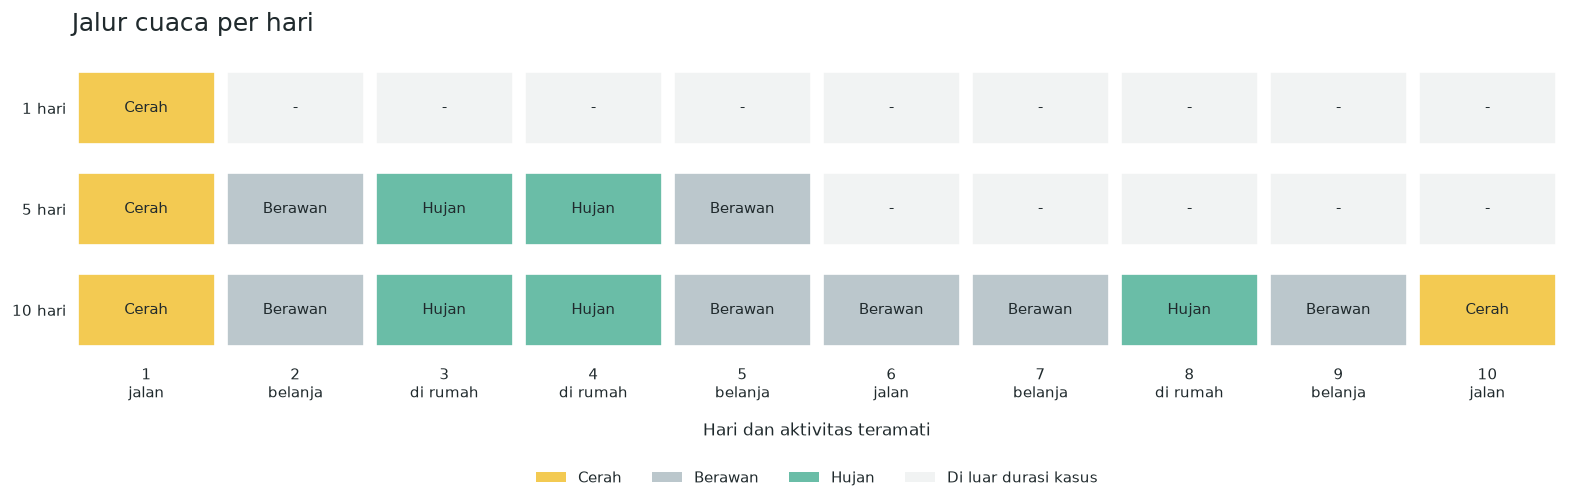

Hari,Aktivitas,Cuaca hasil Viterbi
1,jalan,Cerah


Hari,Aktivitas,Cuaca hasil Viterbi
1,jalan,Cerah
2,belanja,Berawan
3,di_rumah,Hujan
4,di_rumah,Hujan
5,belanja,Berawan


Hari,Aktivitas,Cuaca hasil Viterbi
1,jalan,Cerah
2,belanja,Berawan
3,di_rumah,Hujan
4,di_rumah,Hujan
5,belanja,Berawan
6,jalan,Berawan
7,belanja,Berawan
8,di_rumah,Hujan
9,belanja,Berawan
10,jalan,Cerah


In [5]:
from contextlib import redirect_stdout
from io import StringIO
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

durations = [1, 5, 10]
show_details = True
observations_10_days = model['observations'] + ['belanja', 'di_rumah', 'belanja', 'jalan']

results = []
for days in durations:
    if not 1 <= days <= len(observations_10_days):
        raise ValueError('Jumlah hari melebihi data yang tersedia.')
    observations = observations_10_days[:days]
    trace = StringIO()
    with redirect_stdout(trace):
        path, probability = viterbi(observations, initial, transition, emission, detail=show_details)
    results.append({
        'hari': days, 'observasi': observations, 'jalur': path,
        'probabilitas': probability, 'perhitungan': trace.getvalue(),
    })

display(HTML('<h3>Ringkasan hasil Viterbi</h3>' + html_table(
    ['Kasus', 'Jalur cuaca', 'P gabungan'],
    [[f"{result['hari']} hari", ' -> '.join(result['jalur']), f"{result['probabilitas']:.10g}"]
     for result in results],
)))

colors = {'Cerah': '#f3ca52', 'Berawan': '#bbc7cc', 'Hujan': '#6abda7'}
figure, axis = plt.subplots(figsize=(13, 4), dpi=120, layout='constrained')
figure.set_facecolor('white')
axis.set_facecolor('white')
for row, result in enumerate(results):
    for day in range(1, max(durations) + 1):
        state = result['jalur'][day - 1] if day <= result['hari'] else None
        axis.add_patch(Rectangle(
            (day - 0.46, row - 0.36), 0.92, 0.72,
            facecolor=colors[state] if state else '#f1f3f3', edgecolor='white',
        ))
        axis.text(day, row, state or '-', ha='center', va='center', fontsize=9, color='#202a2d')
axis.set_xlim(0.5, max(durations) + 0.5)
axis.set_ylim(len(results) - 0.5, -0.5)
axis.set_yticks(range(len(results)), [f"{result['hari']} hari" for result in results])
axis.set_xticks(range(1, max(durations) + 1),
    [f'{day}\n{activity.replace("_", " ")}' for day, activity in enumerate(observations_10_days[:max(durations)], start=1)])
axis.tick_params(axis='both', length=0, labelsize=9, colors='#202a2d')
axis.set_title('Jalur cuaca per hari', loc='left', fontsize=15, pad=16, color='#202a2d')
axis.set_xlabel('Hari dan aktivitas teramati', labelpad=12, color='#202a2d')
for spine in axis.spines.values():
    spine.set_visible(False)
legend = [Patch(facecolor=color, label=state) for state, color in colors.items()]
legend.append(Patch(facecolor='#f1f3f3', label='Di luar durasi kasus'))
axis.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, -0.32),
    ncol=4, frameon=False, fontsize=9, labelcolor='#202a2d')
display(figure)
plt.close(figure)

for result in results:
    rows = [[day, observation, state]
            for day, (observation, state) in enumerate(zip(result['observasi'], result['jalur']), start=1)]
    content = html_table(['Hari', 'Aktivitas', 'Cuaca hasil Viterbi'], rows)
    if show_details:
        content += (
            '<details><summary style="cursor:pointer;padding:8px 0;">Perhitungan matematis lengkap</summary>'
            '<pre style="white-space:pre-wrap;overflow-wrap:anywhere;font-size:13px;line-height:1.6;">'
            + escape(result['perhitungan']) + '</pre></details>'
        )
    display(HTML(
        '<details style="margin:12px 0;border-top:1px solid #899499;padding:12px 0;">'
        f'<summary style="cursor:pointer;font-weight:600;">Kasus {result["hari"]} hari | '
        f'P gabungan = {result["probabilitas"]:.10g}</summary>' + content + '</details>'
    ))

In [6]:
from itertools import product
from math import log, isclose, isfinite
from statistics import mean, stdev
from time import perf_counter_ns
import random
import platform
import sys
import csv
import hashlib
import matplotlib
import matplotlib.pyplot as plt

def log_parameters(initial, transition, emission):
    def safe_log(value):
        return log(value) if value > 0 else float('-inf')
    log_initial = {state: safe_log(value) for state, value in initial.items()}
    log_transition = {state: {target: safe_log(value) for target, value in row.items()}
                      for state, row in transition.items()}
    log_emission = {state: {symbol: safe_log(value) for symbol, value in row.items()}
                    for state, row in emission.items()}
    return log_initial, log_transition, log_emission

def viterbi_log(observations, initial, transition, emission):
    if not observations:
        return [], 0.0
    log_initial, log_transition, log_emission = log_parameters(initial, transition, emission)
    states = list(initial)
    scores = {state: log_initial[state] + log_emission[state][observations[0]] for state in states}
    pointers = []
    for observation in observations[1:]:
        next_scores, previous = {}, {}
        for state in states:
            candidates = {origin: scores[origin] + log_transition[origin][state] for origin in states}
            best = max(candidates, key=candidates.get)
            next_scores[state] = candidates[best] + log_emission[state][observation]
            previous[state] = best
        scores = next_scores
        pointers.append(previous)
    last = max(scores, key=scores.get)
    if not isfinite(scores[last]):
        raise ValueError('Tidak ada jalur dengan probabilitas positif.')
    path = [last]
    for previous in reversed(pointers):
        path.append(previous[path[-1]])
    return path[::-1], scores[last]

def exhaustive_log(observations, initial, transition, emission):
    if not observations:
        return [], 0.0
    if len(observations) > 10:
        raise ValueError('Enumerasi dibatasi sampai 10 hari karena biayanya eksponensial.')
    log_initial, log_transition, log_emission = log_parameters(initial, transition, emission)
    best_path, best_score = None, float('-inf')
    for candidate in product(initial, repeat=len(observations)):
        score = log_initial[candidate[0]] + log_emission[candidate[0]][observations[0]]
        for day in range(1, len(observations)):
            score += log_transition[candidate[day - 1]][candidate[day]] + log_emission[candidate[day]][observations[day]]
        if score > best_score:
            best_path, best_score = candidate, score
    if best_path is None:
        raise ValueError('Tidak ada jalur dengan probabilitas positif.')
    return list(best_path), best_score

def path_log_score(path, observations, initial, transition, emission):
    if not observations:
        return 0.0
    log_initial, log_transition, log_emission = log_parameters(initial, transition, emission)
    score = log_initial[path[0]] + log_emission[path[0]][observations[0]]
    for day in range(1, len(observations)):
        score += log_transition[path[day - 1]][path[day]] + log_emission[path[day]][observations[day]]
    return score

benchmark_model = json.loads(dataset_path.read_text(encoding='utf-8'))
benchmark_initial = benchmark_model['initial']
benchmark_transition = benchmark_model['transition']
benchmark_emission = benchmark_model['emission']
benchmark_pattern = benchmark_model['observations'] + ['belanja', 'di_rumah', 'belanja', 'jalan']

def repeated_observations(length):
    return (benchmark_pattern * ((length + len(benchmark_pattern) - 1) // len(benchmark_pattern)))[:length]

for length in [1, 2, 4, 5, 6, 8, 10]:
    sample = repeated_observations(length)
    decoded, log_score = viterbi_log(sample, benchmark_initial, benchmark_transition, benchmark_emission)
    brute_path, brute_score = exhaustive_log(sample, benchmark_initial, benchmark_transition, benchmark_emission)
    old_path, old_score = viterbi(sample, benchmark_initial, benchmark_transition, benchmark_emission, detail=False)
    assert isclose(log_score, brute_score, rel_tol=1e-12, abs_tol=1e-12)
    assert isclose(log_score, path_log_score(decoded, sample, benchmark_initial, benchmark_transition, benchmark_emission), rel_tol=1e-12)
    assert isclose(log_score, log(old_score), rel_tol=1e-12)
    if length in [1, 5, 10]:
        assert decoded == old_path == brute_path
assert viterbi_log([], benchmark_initial, benchmark_transition, benchmark_emission) == ([], 0.0)
print('Lulus: Viterbi log-space cocok dengan enumerasi dan versi perkalian pada 7 ukuran pendek.')

Lulus: Viterbi log-space cocok dengan enumerasi dan versi perkalian pada 7 ukuran pendek.


Kelompok,Algoritma,Hari,Run,Panggilan/batch,Rata-rata (ms),SD (ms),Min (ms),Maks (ms)
pendek,Viterbi,1,10,1000,0.006895,0.001526,0.005999,0.010357
pendek,Enumerasi,1,10,1000,0.007176,0.002642,0.006252,0.014691
pendek,Viterbi,2,10,917,0.009379,0.002677,0.008410,0.016996
pendek,Enumerasi,2,10,961,0.009767,0.001510,0.008717,0.012667
pendek,Viterbi,4,10,668,0.015685,0.005345,0.013006,0.026441
pendek,Enumerasi,4,10,180,0.062905,0.015989,0.055375,0.104119
pendek,Viterbi,5,10,605,0.016458,0.001713,0.015208,0.019996
pendek,Enumerasi,5,10,53,0.220759,0.070703,0.185043,0.404485
pendek,Viterbi,6,10,504,0.020386,0.007175,0.017439,0.040635
pendek,Enumerasi,6,10,15,0.739129,0.203726,0.633116,1.154559


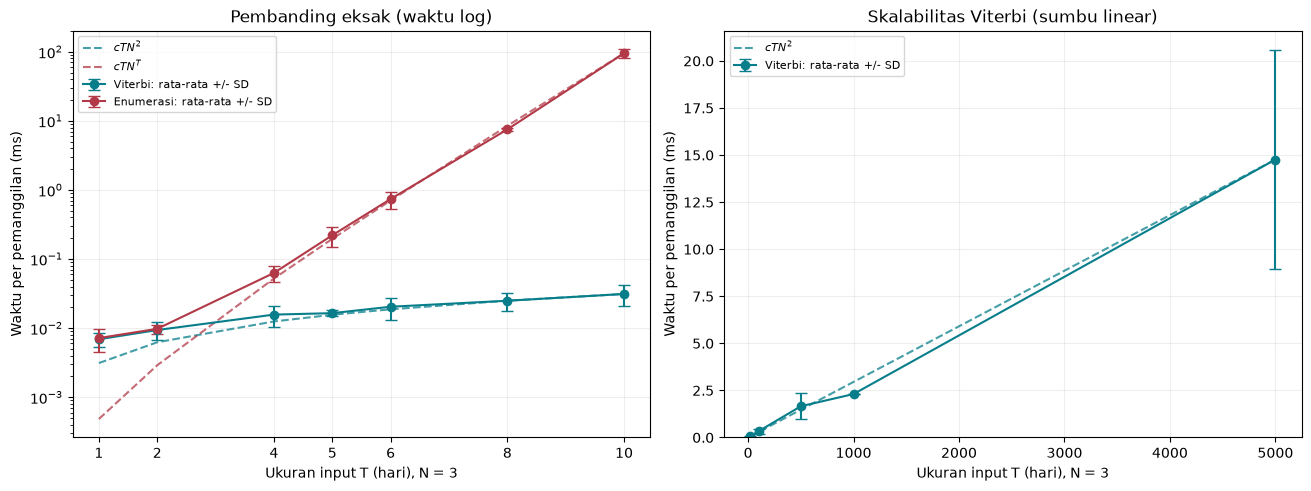

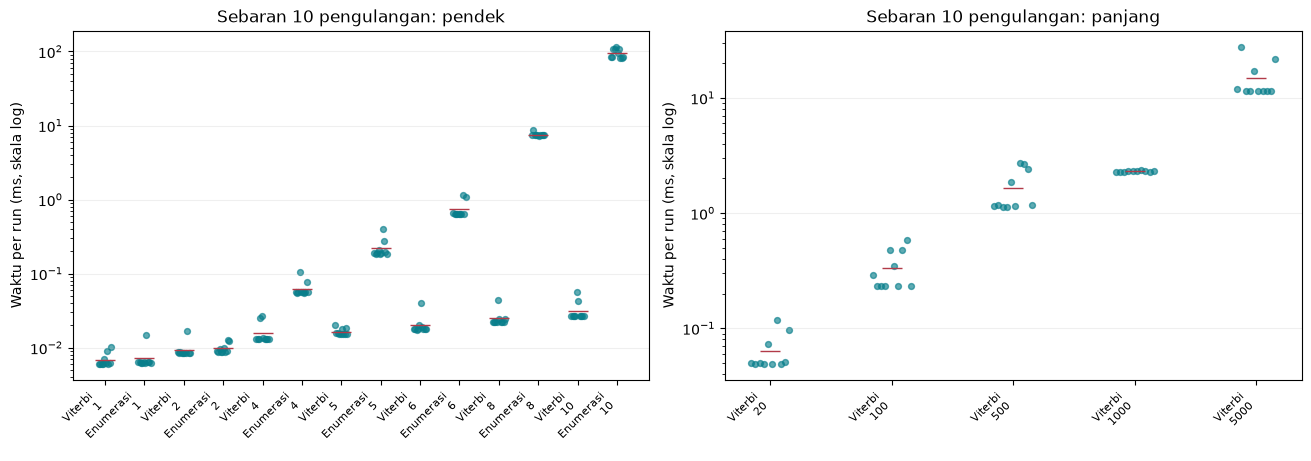

Python 3.14.2 | Linux-6.8.0-1064-azure-x86_64-with-glibc2.39 | x86_64
19 konfigurasi, 190 sampel batch. Output: /workspaces/algoritma_viterbi/output_eksperimen_cuaca
Simpangan baku log-probabilitas semua konfigurasi: 0.0


In [7]:
REPEATS = 10
SEED = 20261011
SHORT_SIZES = [1, 2, 4, 5, 6, 8, 10]
LONG_SIZES = [20, 100, 500, 1000, 5000]
output_directory = root / 'output_eksperimen_cuaca'
output_directory.mkdir(parents=True, exist_ok=True)

def measure_cases(cases):
    plans = []
    for case in cases:
        arguments = (case['observations'], benchmark_initial, case['transition'], case['emission'])
        for warmup in range(2):
            expected = case['function'](*arguments)
        started = perf_counter_ns()
        case['function'](*arguments)
        elapsed = max(perf_counter_ns() - started, 1)
        batch = max(1, min(1000, int(10_000_000 / elapsed)))
        plans.append((case, arguments, expected, batch))
    runs = []
    order_rng = random.Random(SEED)
    for repetition in range(1, REPEATS + 1):
        order = list(range(len(plans)))
        order_rng.shuffle(order)
        for position, index in enumerate(order, start=1):
            case, arguments, expected, batch = plans[index]
            started = perf_counter_ns()
            for call in range(batch):
                measured = case['function'](*arguments)
            elapsed = perf_counter_ns() - started
            assert measured == expected, 'Hasil decoding berubah antar-run.'
            runs.append({
                'group': case['group'], 'algorithm': case['algorithm'],
                'days': len(case['observations']), 'alpha': case.get('alpha', 0.0),
                'beta': case.get('beta', 0.0), 'run': repetition, 'order': position,
                'batch_calls': batch, 'ms_per_call': elapsed / batch / 1_000_000,
                'log_probability': measured[1],
            })
    summaries = []
    for case, arguments, expected, batch in plans:
        selected = [row for row in runs if row['group'] == case['group']
                    and row['algorithm'] == case['algorithm'] and row['days'] == len(case['observations'])
                    and row['alpha'] == case.get('alpha', 0.0) and row['beta'] == case.get('beta', 0.0)]
        times = [row['ms_per_call'] for row in selected]
        assert len(times) == REPEATS
        summaries.append({
            'group': case['group'], 'algorithm': case['algorithm'], 'days': len(case['observations']),
            'alpha': case.get('alpha', 0.0), 'beta': case.get('beta', 0.0),
            'runs': REPEATS, 'batch_calls': batch, 'mean_ms': mean(times), 'sd_ms': stdev(times),
            'min_ms': min(times), 'max_ms': max(times),
            'mean_log_probability': mean(row['log_probability'] for row in selected),
            'sd_log_probability': stdev(row['log_probability'] for row in selected),
        })
    return runs, summaries

def save_csv(filename, rows):
    with (output_directory / filename).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

benchmark_cases = []
for length in SHORT_SIZES:
    sample = repeated_observations(length)
    for algorithm, decoder in [('Viterbi', viterbi_log), ('Enumerasi', exhaustive_log)]:
        benchmark_cases.append({'group': 'pendek', 'algorithm': algorithm, 'function': decoder,
                                'observations': sample, 'transition': benchmark_transition,
                                'emission': benchmark_emission})
for length in LONG_SIZES:
    benchmark_cases.append({'group': 'panjang', 'algorithm': 'Viterbi', 'function': viterbi_log,
                            'observations': repeated_observations(length),
                            'transition': benchmark_transition, 'emission': benchmark_emission})

timing_runs, timing_summary = measure_cases(benchmark_cases)
save_csv('waktu_per_run.csv', timing_runs)
save_csv('ringkasan_waktu.csv', timing_summary)
display(HTML('<h3>Waktu per pemanggilan: rata-rata dan simpangan baku sampel</h3>' + html_table(
    ['Kelompok', 'Algoritma', 'Hari', 'Run', 'Panggilan/batch', 'Rata-rata (ms)', 'SD (ms)', 'Min (ms)', 'Maks (ms)'],
    [[row['group'], row['algorithm'], row['days'], row['runs'], row['batch_calls'],
      f"{row['mean_ms']:.6f}", f"{row['sd_ms']:.6f}", f"{row['min_ms']:.6f}", f"{row['max_ms']:.6f}"]
     for row in timing_summary],
)))

timing_figure, timing_axes = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
theory_curves = []
state_count = len(benchmark_initial)
for axis, group in zip(timing_axes, ['pendek', 'panjang']):
    for algorithm, color in [('Viterbi', '#087e8b'), ('Enumerasi', '#b23a48')]:
        selected = [row for row in timing_summary if row['group'] == group and row['algorithm'] == algorithm]
        if not selected:
            continue
        lengths = [row['days'] for row in selected]
        means = [row['mean_ms'] for row in selected]
        deviations = [row['sd_ms'] for row in selected]
        axis.errorbar(lengths, means, yerr=deviations, marker='o', capsize=4, color=color,
                      label=f'{algorithm}: rata-rata +/- SD')
        costs = [length * (state_count ** 2 if algorithm == 'Viterbi' else state_count ** length)
                 for length in lengths]
        scale = means[-1] / costs[-1]
        theory = [scale * cost for cost in costs]
        complexity = r'$cTN^2$' if algorithm == 'Viterbi' else r'$cTN^T$'
        axis.plot(lengths, theory, '--', color=color, alpha=0.75, label=complexity)
        theory_curves.extend({'group': group, 'algorithm': algorithm, 'days': length,
                              'theoretical_cost': cost, 'scaled_ms': scaled, 'scale_ms': scale}
                             for length, cost, scaled in zip(lengths, costs, theory))
    axis.set_title('Pembanding eksak (waktu log)' if group == 'pendek' else 'Skalabilitas Viterbi (sumbu linear)')
    axis.set_xlabel('Ukuran input T (hari), N = 3')
    axis.set_ylabel('Waktu per pemanggilan (ms)')
    if group == 'pendek':
        axis.set_yscale('log')
        axis.set_xticks(SHORT_SIZES)
    else:
        axis.set_ylim(bottom=0)
    axis.grid(alpha=0.2)
    axis.legend(fontsize=8)
timing_figure.savefig(output_directory / 'waktu_vs_ukuran.png', dpi=180, bbox_inches='tight')
display(timing_figure)
plt.close(timing_figure)
save_csv('kurva_teoritis.csv', theory_curves)

spread_figure, spread_axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
for axis, group in zip(spread_axes, ['pendek', 'panjang']):
    selected = [row for row in timing_summary if row['group'] == group]
    for position, summary in enumerate(selected):
        samples = [row['ms_per_call'] for row in timing_runs if row['group'] == group
                   and row['algorithm'] == summary['algorithm'] and row['days'] == summary['days']]
        offsets = [(run - (REPEATS - 1) / 2) * 0.035 for run in range(REPEATS)]
        axis.scatter([position + offset for offset in offsets], samples, s=18, alpha=0.65, color='#087e8b')
        axis.plot(position, summary['mean_ms'], marker='_', color='#b23a48', markersize=14)
    axis.set_xticks(range(len(selected)), [f"{row['algorithm']}\n{row['days']}" for row in selected],
                    rotation=45, ha='right', fontsize=8)
    axis.set_yscale('log')
    axis.set_ylabel('Waktu per run (ms, skala log)')
    axis.set_title(f'Sebaran 10 pengulangan: {group}')
    axis.grid(axis='y', alpha=0.2)
spread_figure.savefig(output_directory / 'sebaran_waktu.png', dpi=180, bbox_inches='tight')
display(spread_figure)
plt.close(spread_figure)

environment = {
    'python': sys.version, 'executable': sys.executable, 'os': platform.platform(),
    'processor': platform.processor(), 'machine': platform.machine(),
    'matplotlib': matplotlib.__version__, 'seed_order': SEED, 'repeats': REPEATS,
    'warmup_calls': 2, 'target_batch_ms': 10, 'max_batch_calls': 1000,
    'short_sizes': SHORT_SIZES, 'long_sizes': LONG_SIZES,
    'states': list(benchmark_initial), 'observation_pattern': benchmark_pattern,
    'dataset_sha256': hashlib.sha256(dataset_path.read_bytes()).hexdigest(),
    'timer': 'perf_counter_ns', 'sd': 'sample, ddof=1',
    'scope': 'log conversion, decoding, backtracking; excludes input, validation and presentation',
}
(output_directory / 'lingkungan.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print(f'Python {platform.python_version()} | {platform.platform()} | {platform.processor()}')
print(f'{len(timing_summary)} konfigurasi, {len(timing_runs)} sampel batch. Output: {output_directory}')
print('Simpangan baku log-probabilitas semua konfigurasi:', max(row['sd_log_probability'] for row in timing_summary))

Parameter,Alpha,Beta,Rata-rata ms,SD ms,Label berubah (%),Perpindahan,Log P / hari,SD log P
alpha,0.0,0.0,1.319340,0.399867,0.00,300,-1.609605,0.0
alpha,0.25,0.0,1.512875,0.358225,29.80,101,-1.624308,0.0
alpha,0.5,0.0,1.336833,0.458476,50.00,0,-1.479652,0.0
alpha,0.75,0.0,1.234762,0.226002,50.00,0,-1.285884,0.0
alpha,1.0,0.0,1.634010,0.835590,50.00,0,-1.123690,0.0
beta,0.0,0.0,1.299399,0.322211,0.00,300,-1.609605,0.0
beta,0.0,0.25,1.421961,0.383178,40.00,200,-1.632139,0.0
beta,0.0,0.5,1.289326,0.282057,80.00,0,-1.542976,0.0
beta,0.0,0.75,1.202782,0.195562,80.00,0,-1.482932,0.0
beta,0.0,1.0,1.427417,0.348329,80.00,0,-1.455960,0.0


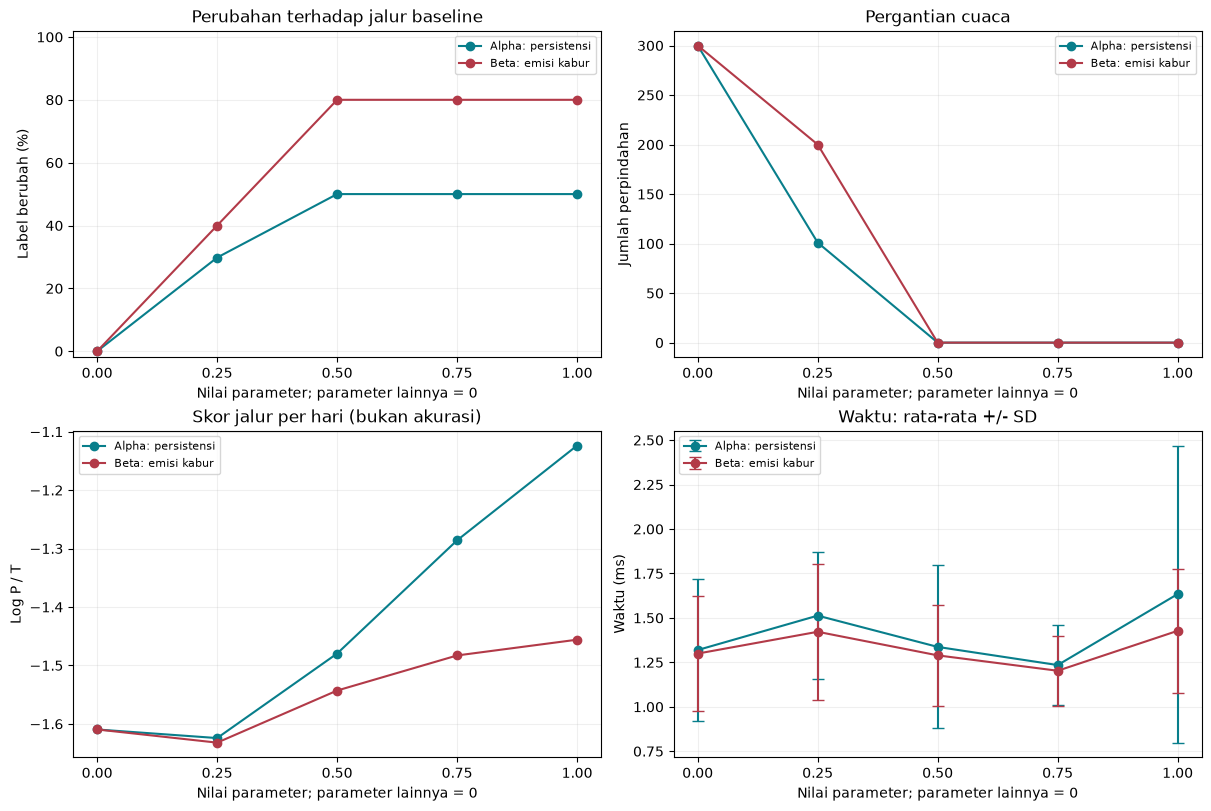

Lulus: 10 konfigurasi sensitivitas, 100 sampel, semua matriks valid.
Laporan: /workspaces/algoritma_viterbi/output_eksperimen_cuaca/hasil_eksperimen.md
Ada konfigurasi dengan SD > 50% rata-rata. Lihat catatan variasi waktu dalam laporan; semua sampel dipertahankan.


In [8]:
SENSITIVITY_SIZE = 500
PARAMETER_VALUES = [0.0, 0.25, 0.5, 0.75, 1.0]
sensitivity_input = repeated_observations(SENSITIVITY_SIZE)
baseline_path, baseline_log_score = viterbi_log(
    sensitivity_input, benchmark_initial, benchmark_transition, benchmark_emission)

def varied_parameters(alpha, beta):
    if not (0 <= alpha <= 1 and 0 <= beta <= 1):
        raise ValueError('Alpha dan beta harus berada dalam [0, 1].')
    transitions = {origin: {target: (1 - alpha) * value + alpha * (origin == target)
                            for target, value in row.items()}
                   for origin, row in benchmark_transition.items()}
    emissions = {state: {symbol: (1 - beta) * value + beta / len(row)
                          for symbol, value in row.items()}
                 for state, row in benchmark_emission.items()}
    for row in list(transitions.values()) + list(emissions.values()):
        assert all(0 <= value <= 1 for value in row.values())
        assert isclose(sum(row.values()), 1.0, abs_tol=1e-12)
    return transitions, emissions

sensitivity_cases = []
for parameter in ['alpha', 'beta']:
    for value in PARAMETER_VALUES:
        alpha = value if parameter == 'alpha' else 0.0
        beta = value if parameter == 'beta' else 0.0
        transitions, emissions = varied_parameters(alpha, beta)
        short_input = repeated_observations(5)
        short_decoded, short_score = viterbi_log(short_input, benchmark_initial, transitions, emissions)
        brute_decoded, brute_score = exhaustive_log(short_input, benchmark_initial, transitions, emissions)
        assert isclose(short_score, brute_score, rel_tol=1e-12, abs_tol=1e-12)
        sensitivity_cases.append({'group': parameter, 'algorithm': 'Viterbi', 'function': viterbi_log,
                                  'observations': sensitivity_input, 'transition': transitions,
                                  'emission': emissions, 'alpha': alpha, 'beta': beta})

sensitivity_runs, sensitivity_summary = measure_cases(sensitivity_cases)
sensitivity_paths = []
for case, summary in zip(sensitivity_cases, sensitivity_summary):
    decoded, log_score = viterbi_log(
        sensitivity_input, benchmark_initial, case['transition'], case['emission'])
    assert len(decoded) == SENSITIVITY_SIZE and isfinite(log_score)
    assert isclose(log_score, path_log_score(decoded, sensitivity_input, benchmark_initial,
                                           case['transition'], case['emission']), rel_tol=1e-12)
    changes = sum(state != reference for state, reference in zip(decoded, baseline_path))
    switches = sum(current != previous for previous, current in zip(decoded, decoded[1:]))
    summary.update({'changed_labels_pct': 100 * changes / SENSITIVITY_SIZE,
                    'switches': switches, 'log_probability_per_day': log_score / SENSITIVITY_SIZE})
    sensitivity_paths.extend({'parameter': case['group'], 'alpha': case['alpha'], 'beta': case['beta'],
                              'day': day, 'observation': observation, 'baseline_state': baseline, 'state': state}
                             for day, (observation, baseline, state) in enumerate(
                                 zip(sensitivity_input, baseline_path, decoded), start=1))
    if case['alpha'] == case['beta'] == 0:
        assert decoded == baseline_path and changes == 0
    if case['alpha'] == 1:
        assert switches == 0
    assert summary['sd_log_probability'] == 0.0

save_csv('sensitivitas_per_run.csv', sensitivity_runs)
save_csv('ringkasan_sensitivitas.csv', sensitivity_summary)
save_csv('jalur_sensitivitas.csv', sensitivity_paths)
display(HTML('<h3>Sensitivitas parameter: T = 500, masing-masing 10 pengulangan</h3>' + html_table(
    ['Parameter', 'Alpha', 'Beta', 'Rata-rata ms', 'SD ms', 'Label berubah (%)', 'Perpindahan', 'Log P / hari', 'SD log P'],
    [[row['group'], row['alpha'], row['beta'], f"{row['mean_ms']:.6f}", f"{row['sd_ms']:.6f}",
      f"{row['changed_labels_pct']:.2f}", row['switches'], f"{row['log_probability_per_day']:.6f}",
      row['sd_log_probability']] for row in sensitivity_summary],
)))

sensitivity_figure, sensitivity_axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for parameter, color, label in [('alpha', '#087e8b', 'Alpha: persistensi'), ('beta', '#b23a48', 'Beta: emisi kabur')]:
    selected = [row for row in sensitivity_summary if row['group'] == parameter]
    values = [row[parameter] for row in selected]
    sensitivity_axes[0, 0].plot(values, [row['changed_labels_pct'] for row in selected], 'o-', color=color, label=label)
    sensitivity_axes[0, 1].plot(values, [row['switches'] for row in selected], 'o-', color=color, label=label)
    sensitivity_axes[1, 0].plot(values, [row['log_probability_per_day'] for row in selected], 'o-', color=color, label=label)
    sensitivity_axes[1, 1].errorbar(values, [row['mean_ms'] for row in selected],
                                   yerr=[row['sd_ms'] for row in selected], fmt='o-',
                                   capsize=4, color=color, label=label)
for axis, title, ylabel in zip(sensitivity_axes.flat,
    ['Perubahan terhadap jalur baseline', 'Pergantian cuaca', 'Skor jalur per hari (bukan akurasi)', 'Waktu: rata-rata +/- SD'],
    ['Label berubah (%)', 'Jumlah perpindahan', 'Log P / T', 'Waktu (ms)']):
    axis.set_title(title)
    axis.set_xlabel('Nilai parameter; parameter lainnya = 0')
    axis.set_ylabel(ylabel)
    axis.set_xticks(PARAMETER_VALUES)
    axis.grid(alpha=0.2)
    axis.legend(fontsize=8)
sensitivity_axes[0, 0].set_ylim(-2, 102)
sensitivity_figure.savefig(output_directory / 'sensitivitas_parameter.png', dpi=180, bbox_inches='tight')
display(sensitivity_figure)
plt.close(sensitivity_figure)

environment.update({'sensitivity_size': SENSITIVITY_SIZE, 'parameter_values': PARAMETER_VALUES,
                    'alpha_definition': '(1-alpha) A + alpha I',
                    'beta_definition': '(1-beta) B + beta U', 'sensitivity_design': 'one at a time'})
(output_directory / 'lingkungan.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')

report = [
    '# Hasil Eksperimen Viterbi Cuaca', '',
    'Hasil dihasilkan dari eksekusi notebook, bukan angka waktu yang diperkirakan.', '',
    '## Metode',
    f'- Python {platform.python_version()}; {platform.platform()}; {platform.processor()}.',
    f'- Seed urutan benchmark: {SEED}; algoritma dan data deterministik.',
    '- Input: pola 10 aktivitas sintetis diulang; N=3 dan M=3 tetap. JSON asli tidak diubah.',
    f'- Ukuran pembanding ({len(SHORT_SIZES)}): {", ".join(map(str, SHORT_SIZES))} hari; '
    f'ukuran panjang ({len(LONG_SIZES)}): {", ".join(map(str, LONG_SIZES))} hari.',
    '- Viterbi log-space dibandingkan dengan enumerasi lengkap log-space (maksimal 10 hari).',
    '- Per konfigurasi: 2 warm-up, kalibrasi batch target 10 ms (maksimal 1000 panggilan), lalu 10 run.',
    '- Satu sampel adalah waktu batch / jumlah panggilan; SD sampel menggunakan pembagi R-1.',
    '- Timer perf_counter_ns mencakup konversi log, decoding, dan backtracking; tidak mencakup input, I/O, validasi, atau visualisasi.',
    '- Urutan konfigurasi diacak per run. Semua waktu disertakan tanpa pembuangan outlier.',
    '- Kurva teori c*T*N^2 dan c*T*N^T ditambatkan pada rata-rata ukuran terbesar masing-masing seri.',
    '- Error bar +/- 1 SD, bukan confidence interval. Bagian di bawah nol tidak terlihat pada sumbu waktu nonnegatif.',
    '- Dua parameter diuji satu per satu, T=500: A_alpha=(1-alpha)A+alpha*I; B_beta=(1-beta)B+beta*U.',
    '- Nilai parameter: 0, 0.25, 0.5, 0.75, 1; parameter lainnya=0; peluang awal tetap.', '',
    '## Waktu Eksekusi', '',
    '| Kelompok | Algoritma | T | Run | Panggilan/batch | Rata-rata ms | SD ms | Min ms | Maks ms |',
    '|---|---|---:|---:|---:|---:|---:|---:|---:|',
 ]
for row in timing_summary:
    report.append(f"| {row['group']} | {row['algorithm']} | {row['days']} | {row['runs']} | {row['batch_calls']} | "
                  f"{row['mean_ms']:.6f} | {row['sd_ms']:.6f} | {row['min_ms']:.6f} | {row['max_ms']:.6f} |")
report += ['', '![Waktu dan kurva teori](waktu_vs_ukuran.png)', '',
           '![Sebaran setiap run; garis merah adalah rata-rata](sebaran_waktu.png)', '',
           '## Sensitivitas', '',
           '| Parameter | Alpha | Beta | Rata-rata ms | SD ms | Label berubah % | Perpindahan | Log P / hari | SD log P |',
           '|---|---:|---:|---:|---:|---:|---:|---:|---:|']
for row in sensitivity_summary:
    report.append(f"| {row['group']} | {row['alpha']} | {row['beta']} | {row['mean_ms']:.6f} | "
                  f"{row['sd_ms']:.6f} | {row['changed_labels_pct']:.2f} | {row['switches']} | "
                  f"{row['log_probability_per_day']:.6f} | {row['sd_log_probability']:.1f} |")
report += ['', '![Sensitivitas dua parameter](sensitivitas_parameter.png)', '', '## Interpretasi dan Validasi', '']
short_viterbi = next(row for row in timing_summary if row['algorithm'] == 'Viterbi' and row['days'] == 10)
short_brute = next(row for row in timing_summary if row['algorithm'] == 'Enumerasi' and row['days'] == 10)
report.append(f"- Pada T=10, rasio rata-rata waktu enumerasi / Viterbi = {short_brute['mean_ms'] / short_viterbi['mean_ms']:.2f}. "
              'Rasio ini hanya berlaku untuk implementasi dan pengukuran lokal ini.')
report.append('- Skor Viterbi cocok dengan enumerasi pada 7 ukuran pendek dan 10 konfigurasi sensitivitas (prefix 5 hari). '
              'Jalur 1/5/10 hari cocok dengan versi perkalian; skor jalur sensitivitas dihitung ulang secara independen.')
report.append(f'- Semua {len(timing_runs) + len(sensitivity_runs)} sampel benchmark dan sensitivitas menghasilkan keluaran yang tetap; SD log-probabilitas antar-run = 0. '
              'Tidak ada sebaran hasil stokastik karena kedua algoritma deterministik. Sebaran waktu tetap dilaporkan.')
for parameter in ['alpha', 'beta']:
    endpoint = next(row for row in sensitivity_summary if row['group'] == parameter and row[parameter] == 1)
    report.append(f"- Pada {parameter}=1: {endpoint['changed_labels_pct']:.2f}% label berubah dari baseline; "
                  f"{endpoint['switches']} perpindahan cuaca. Ini sensitivitas jalur, bukan penurunan/peningkatan akurasi.")
noisy = [row for row in timing_summary + sensitivity_summary if row['sd_ms'] > 0.5 * row['mean_ms']]
if noisy:
    for row in noisy:
        report.append(f"- Variasi waktu besar: {row['group']}, {row['algorithm']}, T={row['days']}, "
                      f"alpha={row['alpha']}, beta={row['beta']}: rata-rata {row['mean_ms']:.6f} ms, SD {row['sd_ms']:.6f} ms, "
                      f"rentang {row['min_ms']:.6f}-{row['max_ms']:.6f} ms. Tidak ada sampel yang dihapus. "
                      'Penyebab gangguan belum diisolasi; rata-rata pada titik acuan dapat menggeser kurva teori.')
report += ['- Grafik tidak membuktikan kompleksitas asimtotik. Overhead konversi log lebih terasa pada T kecil; '
           'variasi wall-clock dapat mengganggu bentuk kurva. Bukti O(TN^2) berasal dari struktur perulangan Viterbi.',
           '- Percobaan dibatasi satu pola sintetis dan satu lingkungan/proses. N tidak divariasikan; interaksi alpha-beta tidak diuji. '
           'Label sebenarnya tidak tersedia, sehingga tidak dilaporkan akurasi cuaca.',
           '- Skor log P antar-model bukan ukuran mutu prediksi dan tidak dibandingkan sebagai akurasi.', '',
           '## Artefak Reproduksi', '',
           '- waktu_per_run.csv, ringkasan_waktu.csv, kurva_teoritis.csv',
           '- sensitivitas_per_run.csv, ringkasan_sensitivitas.csv, jalur_sensitivitas.csv',
           '- lingkungan.json: interpreter, OS, CPU, seed, konfigurasi, dan hash dataset.',
           '- Jalankan semua sel notebook untuk mengulangi pengukuran. Waktu berubah antar-eksekusi; berkas hasil diperbarui.',
           '- Laporan PDF IEEE sebelumnya belum diperbarui dengan eksperimen tambahan ini.']
(output_directory / 'hasil_eksperimen.md').write_text('\n'.join(report) + '\n', encoding='utf-8')
print(f'Lulus: {len(sensitivity_summary)} konfigurasi sensitivitas, {len(sensitivity_runs)} sampel, semua matriks valid.')
print(f'Laporan: {output_directory / "hasil_eksperimen.md"}')
if noisy:
    print('Ada konfigurasi dengan SD > 50% rata-rata. Lihat catatan variasi waktu dalam laporan; semua sampel dipertahankan.')